## Import library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

### Définir le chemin des données

In [2]:
DATA_DIR = Path("../jeu_donnees_referentiel_produit")

fichiers = {
    "PIM": DATA_DIR / "01_PIM_catalogue_produits.csv",
    "ERP": DATA_DIR / "02_ERP_articles.csv",
    "Marketplace": DATA_DIR / "03_Marketplace_offres_vendeurs.csv"
}

### Charger les trois sources

In [3]:
pim = pd.read_csv(fichiers["PIM"])
erp = pd.read_csv(fichiers["ERP"])
marketplace = pd.read_csv(fichiers["Marketplace"])

### Vérifier le chargement

In [4]:
for nom, df in {
    "PIM": pim,
    "ERP": erp,
    "Marketplace": marketplace
}.items():
    print(f"\n===== {nom} =====")
    print("Dimensions :", df.shape)
    display(df.head())


===== PIM =====
Dimensions : (102, 11)


,product_id,product_name,brand,category,gtin,model,specification,color,status,created_at,updated_at
0,P0001,Samsung Galaxy S24 128 Go,Samsung,Smartphone,3700000000001,Galaxy S24,128 Go,Noir,ACTIVE,2025-02-02,2026-02-02
1,P0002,Apple iPhone 15 128 Go,Apple,Smartphone,3700000000002,iPhone 15,128 Go,Noir,ACTIVE,2025-03-03,2026-03-03
2,P0003,Apple iPhone 15 Pro 256 Go,Apple,Smartphone,3700000000003,iPhone 15 Pro,256 Go,Titane,ACTIVE,2025-04-04,2026-04-04
3,P0004,Xiaomi Redmi Note 13 256 Go,Xiaomi,Smartphone,3700000000004,Redmi Note 13,256 Go,Noir,ACTIVE,2025-05-05,2026-05-05
4,P0005,Google Pixel 8 128 Go,Google,Smartphone,3700000000005,Pixel 8,128 Go,Noir,ACTIVE,2025-06-06,2026-06-06



===== ERP =====
Dimensions : (101, 11)


,article_id,libelle_article,marque,famille_article,code_barres,modele,caracteristique,couleur,prix_achat,statut,date_maj
0,ART-1001,SAMSUNG - Galaxy S24 128 Go,SAMSUNG,Smartphone,3.700000e+12,Galaxy S24,128 Go,Noir,2982.11,ACTIF,2025-02-02
1,ART-1002,APPLE - iPhone 15 128 Go,APPLE,Smartphone,3.700000e+12,iPhone 15,128 Go,Noir,7409.34,ACTIF,2025-03-03
2,ART-1003,APPLE - iPhone 15 Pro 256 Go,APPLE,Smartphone,3.700000e+12,iPhone 15 Pro,256 Go,Titane,433.71,ACTIF,2025-04-04
3,ART-1004,XIAOMI - Redmi Note 13 256 Go,XIAOMI,Smartphone,3.700000e+12,Redmi Note 13,256 Go,Noir,626.08,ACTIF,2025-05-05
4,ART-1005,GOOGLE - Pixel 8 128 Go,GOOGLE,Smartphone,3.700000e+12,Pixel 8,128 Go,Noir,5236.22,ACTIF,2025-06-06



===== Marketplace =====
Dimensions : (110, 13)


,offer_id,seller_sku,seller_id,titre_annonce,brand_name,category_name,barcode,variant,color_name,price_mad,stock_quantity,offer_status,last_updated
0,OFF-5001,SKU-0001,SELLER-02,Samsung Galaxy S24 128 Go,Samsung,Smartphone,3700000000001,128 Go,Noir,1937.56,0.0,ACTIVE,2026-02-02
1,OFF-5002,SKU-0002,SELLER-03,Apple iPhone 15 128 Go,Apple,Smartphone,3700000000002,128 Go,Noir,1265.44,0.0,ACTIVE,2026-03-03
2,OFF-5003,SKU-0003,SELLER-04,Apple iPhone 15 Pro 256 Go,Apple,Smartphone,3700000000003,256 Go,Titane,5288.70,1.0,ACTIVE,2026-04-04
3,OFF-7003,ALT-003,SELLER-09,Apple iPhone 15 Pro 256 Go - livraison rapide,Apple,Smartphone,3700000000003,256 Go,Titane,1224.95,30.0,ACTIVE,2026-10-15
4,OFF-5004,SKU-0004,SELLER-05,Xiaomi Redmi Note 13 256 Go,Xiaomi,Smartphone,3700000000004,256 Go,Noir,6850.63,10.0,ACTIVE,2026-05-05


In [5]:
sources = {
    "PIM": pim,
    "ERP": erp,
    "Marketplace": marketplace
}

### Examiner la structure de chaque source

In [6]:
for nom, df in sources.items():
    print(f"\n{'='*50}")
    print(f"SOURCE : {nom}")
    print(f"{'='*50}")

    df.info()


SOURCE : PIM
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102 entries, 0 to 101
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     102 non-null    object
 1   product_name   97 non-null     object
 2   brand          101 non-null    object
 3   category       102 non-null    object
 4   gtin           95 non-null     object
 5   model          101 non-null    object
 6   specification  69 non-null     object
 7   color          101 non-null    object
 8   status         102 non-null    object
 9   created_at     102 non-null    object
 10  updated_at     100 non-null    object
dtypes: object(11)
memory usage: 8.9+ KB

SOURCE : ERP
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   article_id       101 non-null    object 
 1   libelle_article  10

### Mesurer la complétude

In [7]:
for nom, df in sources.items():

    print(f"\n===== COMPLETUDE : {nom} =====")

    rapport = pd.DataFrame({
        "Valeurs_manquantes": df.isnull().sum(),
        "Taux_manquant_%": (
            df.isnull().mean() * 100
        ).round(2)
    })

    display(rapport.sort_values(
        by="Taux_manquant_%",
        ascending=False
    ))


===== COMPLETUDE : PIM =====


,Valeurs_manquantes,Taux_manquant_%
specification,33,32.35
gtin,7,6.86
product_name,5,4.90
updated_at,2,1.96
brand,1,0.98
color,1,0.98
model,1,0.98
product_id,0,0.00
category,0,0.00
status,0,0.00



===== COMPLETUDE : ERP =====


,Valeurs_manquantes,Taux_manquant_%
caracteristique,32,31.68
code_barres,6,5.94
article_id,0,0.00
marque,0,0.00
libelle_article,0,0.00
famille_article,0,0.00
modele,0,0.00
couleur,0,0.00
prix_achat,0,0.00
statut,0,0.00



===== COMPLETUDE : Marketplace =====


,Valeurs_manquantes,Taux_manquant_%
variant,35,31.82
stock_quantity,11,10.00
brand_name,9,8.18
barcode,5,4.55
color_name,1,0.91
titre_annonce,0,0.00
seller_id,0,0.00
seller_sku,0,0.00
offer_id,0,0.00
category_name,0,0.00


### Vérifier les doublons

In [8]:
for nom, df in sources.items():

    print(f"\n===== DOUBLONS : {nom} =====")

    print("Doublons de lignes :", df.duplicated().sum())

    identifiant = df.columns[0]

    print(
        f"Doublons sur {identifiant} :",
        df[identifiant].duplicated().sum()
    )


===== DOUBLONS : PIM =====
Doublons de lignes : 0
Doublons sur product_id : 0

===== DOUBLONS : ERP =====
Doublons de lignes : 0
Doublons sur article_id : 0

===== DOUBLONS : Marketplace =====
Doublons de lignes : 0
Doublons sur offer_id : 0


### Détecter les anomalies numériques

In [9]:
# ERP : prix d'achat négatifs
print("Prix d'achat négatifs dans ERP :")
display(erp[erp["prix_achat"] < 0])

# Marketplace : prix de vente négatifs
print("Prix de vente négatifs dans Marketplace :")
display(marketplace[marketplace["price_mad"] < 0])

# Marketplace : stocks négatifs
print("Stocks négatifs dans Marketplace :")
display(marketplace[marketplace["stock_quantity"] < 0])

Prix d'achat négatifs dans ERP :


,article_id,libelle_article,marque,famille_article,code_barres,modele,caracteristique,couleur,prix_achat,statut,date_maj
100,ART-DUP-01,Samsung Galaxy S24 128 Go,Samsung,Smartphone,3.700000e+12,Galaxy S24,128 Go,Noir,-50.0,ACTIF,2026-13-01


Prix de vente négatifs dans Marketplace :


,offer_id,seller_sku,seller_id,titre_annonce,brand_name,category_name,barcode,variant,color_name,price_mad,stock_quantity,offer_status,last_updated
109,OFF-ERR-01,SKU-ERR,SELLER-99,???,Marque inconnue,Divers,ABC123,NaN,NaN,-10.0,-5.0,UNKNOWN,2026-02-30


Stocks négatifs dans Marketplace :


,offer_id,seller_sku,seller_id,titre_annonce,brand_name,category_name,barcode,variant,color_name,price_mad,stock_quantity,offer_status,last_updated
6,OFF-5006,SKU-0006,SELLER-07,Sony WH-1000XM5,Sony,Casque audio,3700000000006,NaN,Noir,1728.12,-2.0,ACTIVE,2026-07-07
10,OFF-5009,SKU-0009,SELLER-10,Dell XPS 13 16 Go RAM / 512 Go SSD,Dell,Ordinateur portable,3700000000009,16 Go RAM / 512 Go SSD,Argent,6032.51,-2.0,INACTIVE,2026-10-10
26,OFF-5023,SKU-0023,SELLER-12,Adidas Ultraboost Light 42,Adidas,Chaussures,3700000000023,42,Noir,8240.27,-2.0,ACTIVE,2026-04-24
31,OFF-5028,SKU-0028,SELLER-05,Xiaomi Redmi Note 13 édition 28 256 Go,Xiaomi,Divers,3700000000028,256 Go,Noir,9392.64,-2.0,PENDING,2026-09-02
32,OFF-5029,SKU-0029,SELLER-06,Google Pixel 8 édition 29 128 Go,Google,Smartphone,3700000000029,128 Go,Noir,1376.91,-2.0,ACTIVE,2026-10-03
36,OFF-5033,SKU-0033,SELLER-10,Dell XPS 13 édition 33 16 Go RAM / 512 Go SSD,NaN,Ordinateur portable,3700000000033,16 Go RAM / 512 Go SSD,Argent,2614.24,-2.0,ACTIVE,2026-04-07
57,OFF-5052,SKU-0052,SELLER-05,Xiaomi Redmi Note 13 édition 52 256 Go,Xiaomi,Smartphone,3700000000052,256 Go,Noir,11664.14,-2.0,PENDING,2026-03-26
67,OFF-5061,SKU-0061,SELLER-02,Logitech MX Master 3S édition 61,Logitech,Souris,3700000000061,NaN,Graphite,8000.33,-2.0,ACTIVE,2026-02-08
85,OFF-5078,SKU-0078,SELLER-07,Sony WH-1000XM5 édition 78,Sony,Casque audio,3700000000078,NaN,Noir,11929.76,-2.0,INACTIVE,2026-09-25
104,OFF-5096,SKU-0096,SELLER-01,"Samsonite Guardit 2.0 édition 96 15,6 pouces",Samsonite,Sac à dos,3700000000096,"15,6 pouces",Noir,5447.61,-2.0,PENDING,2026-07-16


In [10]:
for nom, df, colonne in [
    ("PIM", pim, "brand"),
    ("ERP", erp, "marque"),
    ("Marketplace", marketplace, "brand_name")
]:

    print(f"\n===== MARQUES : {nom} =====")

    display(
        df[colonne]
        .value_counts(dropna=False)
        .head(20)
    )


===== MARQUES : PIM =====


brand
Apple        18
Samsung      10
Logitech      8
Xiaomi        5
Google        4
Sony          4
Dell          4
JBL           4
HP            4
Lenovo        4
SanDisk       4
Canon         4
LG            4
Dyson         4
Philips       4
Nespresso     4
Nike          4
Adidas        4
Samsonite     4
NaN           1
Name: count, dtype: int64


===== MARQUES : ERP =====


marque
APPLE        15
SAMSUNG       7
LOGITECH      7
SONY          4
DELL          4
HP            4
XIAOMI        4
CANON         4
SANDISK       4
ADIDAS        4
PHILIPS       4
SAMSONITE     4
DYSON         3
LG            3
GOOGLE        3
JBL           3
NESPRESSO     3
LENOVO        3
NIKE          3
Apple         3
Name: count, dtype: int64


===== MARQUES : Marketplace =====


brand_name
Apple        21
Samsung       9
NaN           9
Logitech      8
Xiaomi        5
Nespresso     5
Sony          4
Samsonite     4
Dell          4
HP            4
Canon         4
LG            4
JBL           4
Philips       4
Dyson         4
Adidas        4
Google        3
SanDisk       3
Lenovo        3
Nike          3
Name: count, dtype: int64

## Étape 4 — Construire le diagnostic qualité

In [11]:
def diagnostic_general(df, nom_source):

    total_cellules = df.shape[0] * df.shape[1]
    cellules_manquantes = df.isna().sum().sum()

    resultat = {
        "Source": nom_source,
        "Nombre de lignes": df.shape[0],
        "Nombre de colonnes": df.shape[1],
        "Doublons exacts": df.duplicated().sum(),
        "Cellules manquantes": cellules_manquantes,
        "Taux de complétude (%)": round(
            (1 - cellules_manquantes / total_cellules) * 100, 2
        ) if total_cellules else 0
    }

    return resultat


resultats = []

for nom, df in sources.items():
    resultats.append(diagnostic_general(df, nom))

rapport_general = pd.DataFrame(resultats)

display(rapport_general)

,Source,Nombre de lignes,Nombre de colonnes,Doublons exacts,Cellules manquantes,Taux de complétude (%)
0,PIM,102,11,0,50,95.54
1,ERP,101,11,0,38,96.58
2,Marketplace,110,13,0,61,95.73


In [12]:
# Calculer le taux de complétude par colonne
def analyser_completude(df, nom_source):

    resultat = pd.DataFrame({
        "Valeurs renseignées": df.notna().sum(),
        "Valeurs manquantes": df.isna().sum(),
        "Taux de complétude (%)": (
            df.notna().mean() * 100
        ).round(2)
    })

    resultat.index.name = "Attribut"

    print(f"\n===== COMPLÉTUDE : {nom_source} =====")

    return resultat.sort_values(
        "Taux de complétude (%)",
        ascending=True
    )

In [13]:
for nom, df in sources.items():

    display(analyser_completude(df, nom))


===== COMPLÉTUDE : PIM =====


,Valeurs renseignées,Valeurs manquantes,Taux de complétude (%)
Attribut,,,
specification,69,33,67.65
gtin,95,7,93.14
product_name,97,5,95.10
updated_at,100,2,98.04
model,101,1,99.02
color,101,1,99.02
brand,101,1,99.02
category,102,0,100.00
product_id,102,0,100.00



===== COMPLÉTUDE : ERP =====


,Valeurs renseignées,Valeurs manquantes,Taux de complétude (%)
Attribut,,,
caracteristique,69,32,68.32
code_barres,95,6,94.06
article_id,101,0,100.00
libelle_article,101,0,100.00
famille_article,101,0,100.00
marque,101,0,100.00
modele,101,0,100.00
couleur,101,0,100.00
prix_achat,101,0,100.00



===== COMPLÉTUDE : Marketplace =====


,Valeurs renseignées,Valeurs manquantes,Taux de complétude (%)
Attribut,,,
variant,75,35,68.18
stock_quantity,99,11,90.00
brand_name,101,9,91.82
barcode,105,5,95.45
color_name,109,1,99.09
seller_id,110,0,100.00
titre_annonce,110,0,100.00
offer_id,110,0,100.00
category_name,110,0,100.00


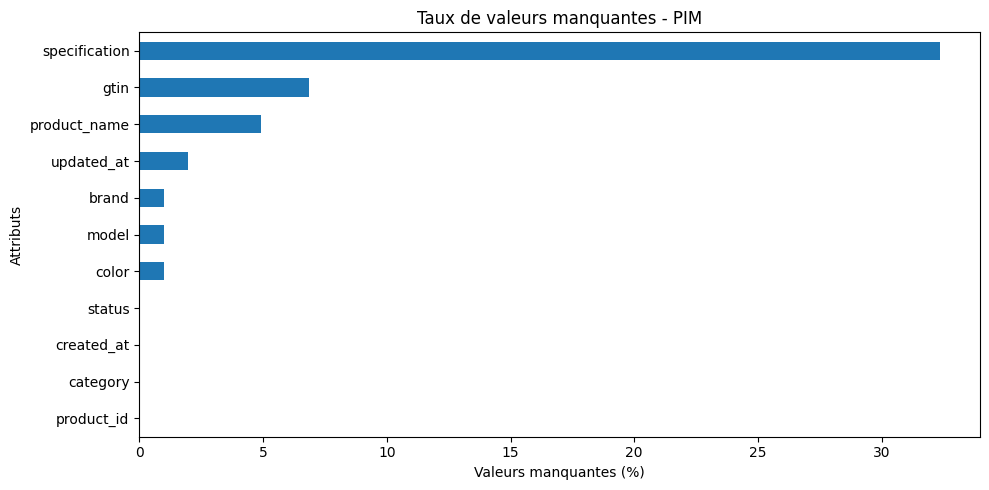

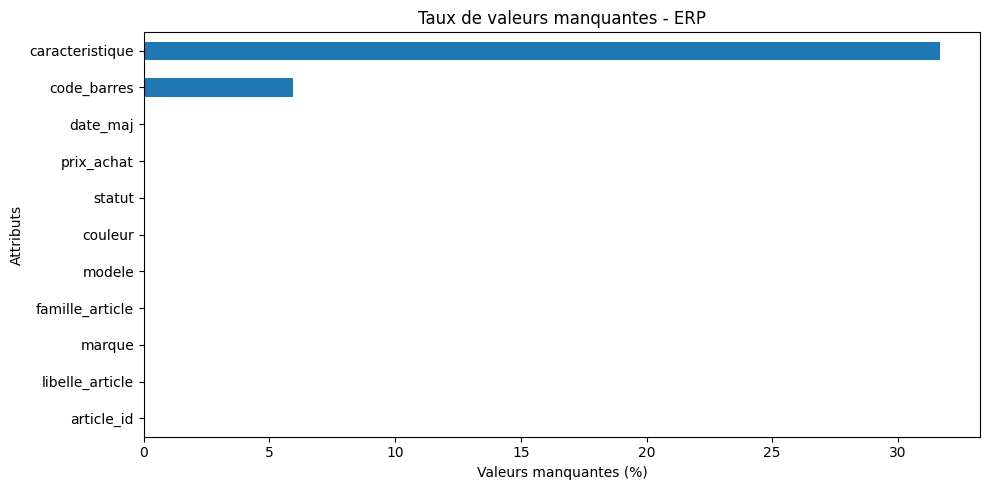

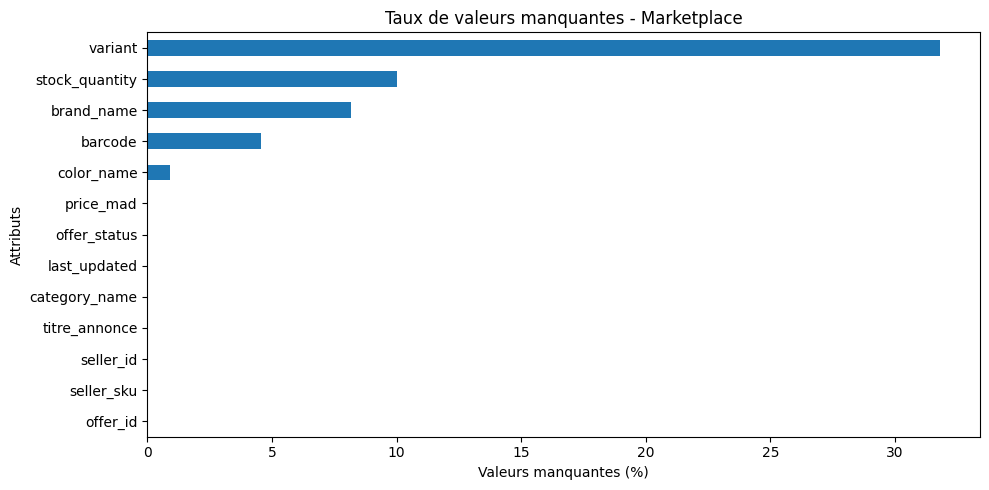

In [14]:
for nom, df in sources.items():

    taux_manquant = (df.isna().mean() * 100).sort_values()

    plt.figure(figsize=(10, 5))

    taux_manquant.plot(kind="barh")

    plt.title(f"Taux de valeurs manquantes - {nom}")
    plt.xlabel("Valeurs manquantes (%)")
    plt.ylabel("Attributs")

    plt.tight_layout()
    plt.show()

In [15]:
# Contrôler les valeurs métier incorrectes
controles = {
    "ERP - Prix d'achat négatif": (
        erp, "prix_achat", lambda x: x < 0
    ),
    "Marketplace - Prix négatif": (
        marketplace, "price_mad", lambda x: x < 0
    ),
    "Marketplace - Stock négatif": (
        marketplace, "stock_quantity", lambda x: x < 0
    )
}

for nom_controle, (df, colonne, condition) in controles.items():

    valeurs = pd.to_numeric(df[colonne], errors="coerce")
    anomalies = df[condition(valeurs)]

    print(f"\n{nom_controle}")
    print("Nombre d'anomalies :", len(anomalies))

    display(anomalies)


ERP - Prix d'achat négatif
Nombre d'anomalies : 1


Attribut,article_id,libelle_article,marque,famille_article,code_barres,modele,caracteristique,couleur,prix_achat,statut,date_maj
100,ART-DUP-01,Samsung Galaxy S24 128 Go,Samsung,Smartphone,3.700000e+12,Galaxy S24,128 Go,Noir,-50.0,ACTIF,2026-13-01



Marketplace - Prix négatif
Nombre d'anomalies : 1


Attribut,offer_id,seller_sku,seller_id,titre_annonce,brand_name,category_name,barcode,variant,color_name,price_mad,stock_quantity,offer_status,last_updated
109,OFF-ERR-01,SKU-ERR,SELLER-99,???,Marque inconnue,Divers,ABC123,NaN,NaN,-10.0,-5.0,UNKNOWN,2026-02-30



Marketplace - Stock négatif
Nombre d'anomalies : 11


Attribut,offer_id,seller_sku,seller_id,titre_annonce,brand_name,category_name,barcode,variant,color_name,price_mad,stock_quantity,offer_status,last_updated
6,OFF-5006,SKU-0006,SELLER-07,Sony WH-1000XM5,Sony,Casque audio,3700000000006,NaN,Noir,1728.12,-2.0,ACTIVE,2026-07-07
10,OFF-5009,SKU-0009,SELLER-10,Dell XPS 13 16 Go RAM / 512 Go SSD,Dell,Ordinateur portable,3700000000009,16 Go RAM / 512 Go SSD,Argent,6032.51,-2.0,INACTIVE,2026-10-10
26,OFF-5023,SKU-0023,SELLER-12,Adidas Ultraboost Light 42,Adidas,Chaussures,3700000000023,42,Noir,8240.27,-2.0,ACTIVE,2026-04-24
31,OFF-5028,SKU-0028,SELLER-05,Xiaomi Redmi Note 13 édition 28 256 Go,Xiaomi,Divers,3700000000028,256 Go,Noir,9392.64,-2.0,PENDING,2026-09-02
32,OFF-5029,SKU-0029,SELLER-06,Google Pixel 8 édition 29 128 Go,Google,Smartphone,3700000000029,128 Go,Noir,1376.91,-2.0,ACTIVE,2026-10-03
36,OFF-5033,SKU-0033,SELLER-10,Dell XPS 13 édition 33 16 Go RAM / 512 Go SSD,NaN,Ordinateur portable,3700000000033,16 Go RAM / 512 Go SSD,Argent,2614.24,-2.0,ACTIVE,2026-04-07
57,OFF-5052,SKU-0052,SELLER-05,Xiaomi Redmi Note 13 édition 52 256 Go,Xiaomi,Smartphone,3700000000052,256 Go,Noir,11664.14,-2.0,PENDING,2026-03-26
67,OFF-5061,SKU-0061,SELLER-02,Logitech MX Master 3S édition 61,Logitech,Souris,3700000000061,NaN,Graphite,8000.33,-2.0,ACTIVE,2026-02-08
85,OFF-5078,SKU-0078,SELLER-07,Sony WH-1000XM5 édition 78,Sony,Casque audio,3700000000078,NaN,Noir,11929.76,-2.0,INACTIVE,2026-09-25
104,OFF-5096,SKU-0096,SELLER-01,"Samsonite Guardit 2.0 édition 96 15,6 pouces",Samsonite,Sac à dos,3700000000096,"15,6 pouces",Noir,5447.61,-2.0,PENDING,2026-07-16


In [16]:
mapping = {
    "PIM": {
        "product_name": "product_name",
        "brand": "brand",
        "category": "category",
        "gtin": "gtin",
        "model": "model",
        "color": "color",
        "specification": "specification"
    },

    "ERP": {
        "product_name": "libelle_article",
        "brand": "marque",
        "category": "famille_article",
        "gtin": "code_barres",
        "model": "modele",
        "color": "couleur",
        "specification": "caracteristique"
    },

    "Marketplace": {
        "product_name": "titre_annonce",
        "brand": "brand_name",
        "category": "category_name",
        "gtin": "barcode",
        "model": None,
        "color": "color_name",
        "specification": "variant"
    }
}

In [17]:
for source, correspondances in mapping.items():
    print(f"\n--- {source} ---")

    for cible, colonne in correspondances.items():
        if colonne is None:
            print(f"{cible}: non disponible dans le mapping initial")
        elif colonne in sources[source].columns:
            print(f"{cible}: OK ({colonne})")
        else:
            print(f"{cible}: COLONNE INTROUVABLE ({colonne})")


--- PIM ---
product_name: OK (product_name)
brand: OK (brand)
category: OK (category)
gtin: OK (gtin)
model: OK (model)
color: OK (color)
specification: OK (specification)

--- ERP ---
product_name: OK (libelle_article)
brand: OK (marque)
category: OK (famille_article)
gtin: OK (code_barres)
model: OK (modele)
color: OK (couleur)
specification: OK (caracteristique)

--- Marketplace ---
product_name: OK (titre_annonce)
brand: OK (brand_name)
category: OK (category_name)
gtin: OK (barcode)
model: non disponible dans le mapping initial
color: OK (color_name)
specification: OK (variant)


In [18]:
def harmoniser_source(df, nom_source, correspondances):

    donnees = pd.DataFrame(index=df.index)

    for attribut_cible, colonne_source in correspondances.items():

        if colonne_source is not None and colonne_source in df.columns:
            donnees[attribut_cible] = df[colonne_source]
        else:
            donnees[attribut_cible] = pd.NA

    donnees["source_system"] = nom_source

    return donnees

In [19]:
pim_harmonise = harmoniser_source(pim, "PIM", mapping["PIM"])
erp_harmonise = harmoniser_source(erp, "ERP", mapping["ERP"])
marketplace_harmonise = harmoniser_source(
    marketplace, "Marketplace", mapping["Marketplace"]
)

In [22]:
donnees_consolidees = pd.concat(
    [
        pim_harmonise,
        erp_harmonise,
        marketplace_harmonise
    ],
    ignore_index=True
)

print("Dimensions :", donnees_consolidees.shape)

display(donnees_consolidees.head(10))

Dimensions : (313, 8)


,product_name,brand,category,gtin,model,color,specification,source_system
0,Samsung Galaxy S24 128 Go,Samsung,Smartphone,3700000000001,Galaxy S24,Noir,128 Go,PIM
1,Apple iPhone 15 128 Go,Apple,Smartphone,3700000000002,iPhone 15,Noir,128 Go,PIM
2,Apple iPhone 15 Pro 256 Go,Apple,Smartphone,3700000000003,iPhone 15 Pro,Titane,256 Go,PIM
3,Xiaomi Redmi Note 13 256 Go,Xiaomi,Smartphone,3700000000004,Redmi Note 13,Noir,256 Go,PIM
4,Google Pixel 8 128 Go,Google,Smartphone,3700000000005,Pixel 8,Noir,128 Go,PIM
5,Sony WH-1000XM5,Sony,Casque audio,3700000000006,WH-1000XM5,Noir,NaN,PIM
6,JBL Tune 760NC,JBL,Casque audio,3700000000007,Tune 760NC,Noir,NaN,PIM
7,Apple AirPods Pro 2,Apple,Écouteurs,3700000000008,AirPods Pro 2,Blanc,NaN,PIM
8,Dell XPS 13 16 Go RAM / 512 Go SSD,Dell,Ordinateur portable,3700000000009,XPS 13,Argent,16 Go RAM / 512 Go SSD,PIM
9,HP Pavilion 15 8 Go RAM / 512 Go SSD,HP,Ordinateur portable,3700000000010,Pavilion 15,Argent,8 Go RAM / 512 Go SSD,PIM


## Normalisation des données

In [23]:
colonnes_textuelles = [
    "product_name",
    "brand",
    "category",
    "model",
    "color",
    "specification"
]

def normaliser_texte(valeur):

    if pd.isna(valeur):
        return pd.NA

    return " ".join(str(valeur).strip().split()).casefold()


donnees_normalisees = donnees_consolidees.copy()

for colonne in colonnes_textuelles:
    donnees_normalisees[colonne] = (
        donnees_normalisees[colonne].apply(normaliser_texte)
    )

display(donnees_normalisees.head(10))

,product_name,brand,category,gtin,model,color,specification,source_system
0,samsung galaxy s24 128 go,samsung,smartphone,3700000000001,galaxy s24,noir,128 go,PIM
1,apple iphone 15 128 go,apple,smartphone,3700000000002,iphone 15,noir,128 go,PIM
2,apple iphone 15 pro 256 go,apple,smartphone,3700000000003,iphone 15 pro,titane,256 go,PIM
3,xiaomi redmi note 13 256 go,xiaomi,smartphone,3700000000004,redmi note 13,noir,256 go,PIM
4,google pixel 8 128 go,google,smartphone,3700000000005,pixel 8,noir,128 go,PIM
5,sony wh-1000xm5,sony,casque audio,3700000000006,wh-1000xm5,noir,<NA>,PIM
6,jbl tune 760nc,jbl,casque audio,3700000000007,tune 760nc,noir,<NA>,PIM
7,apple airpods pro 2,apple,écouteurs,3700000000008,airpods pro 2,blanc,<NA>,PIM
8,dell xps 13 16 go ram / 512 go ssd,dell,ordinateur portable,3700000000009,xps 13,argent,16 go ram / 512 go ssd,PIM
9,hp pavilion 15 8 go ram / 512 go ssd,hp,ordinateur portable,3700000000010,pavilion 15,argent,8 go ram / 512 go ssd,PIM


In [24]:
OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

donnees_consolidees.to_csv(
    OUTPUT_DIR / "donnees_consolidees.csv",
    index=False
)

donnees_normalisees.to_csv(
    OUTPUT_DIR / "donnees_normalisees.csv",
    index=False
)

print("Fichiers sauvegardés avec succès.")

Fichiers sauvegardés avec succès.


### 4.2 - Catalogue des règles de qualité

In [25]:
# Formaliser le catalogue des règles
regles_qualite = pd.DataFrame([
    ["DQ01", "Complétude", "Nom produit obligatoire", "product_name"],
    ["DQ02", "Complétude", "Marque obligatoire", "brand"],
    ["DQ03", "Complétude", "Catégorie obligatoire", "category"],
    ["DQ04", "Validité", "GTIN au format numérique et longueur autorisée", "gtin"],
    ["DQ05", "Validité", "Prix d'achat positif ou nul", "prix_achat"],
    ["DQ06", "Validité", "Prix de vente positif ou nul", "price_mad"],
    ["DQ07", "Validité", "Stock positif ou nul", "stock_quantity"],
    ["DQ08", "Unicité", "Absence de doublons exacts", "toutes les colonnes"],
    ["DQ09", "Cohérence", "Homogénéité des marques", "brand"],
    ["DQ10", "Cohérence", "Cohérence des GTIN entre sources", "gtin"],
], columns=[
    "ID règle", "Dimension", "Description", "Attribut concerné"
])

display(regles_qualite)

,ID règle,Dimension,Description,Attribut concerné
0,DQ01,Complétude,Nom produit obligatoire,product_name
1,DQ02,Complétude,Marque obligatoire,brand
2,DQ03,Complétude,Catégorie obligatoire,category
3,DQ04,Validité,GTIN au format numérique et longueur autorisée,gtin
4,DQ05,Validité,Prix d'achat positif ou nul,prix_achat
5,DQ06,Validité,Prix de vente positif ou nul,price_mad
6,DQ07,Validité,Stock positif ou nul,stock_quantity
7,DQ08,Unicité,Absence de doublons exacts,toutes les colonnes
8,DQ09,Cohérence,Homogénéité des marques,brand
9,DQ10,Cohérence,Cohérence des GTIN entre sources,gtin


In [26]:
def controle_completude(df, colonnes, nom_source):

    resultats = []

    for colonne in colonnes:

        if colonne not in df.columns:
            continue

        total = len(df)
        manquantes = df[colonne].isna().sum()

        taux = (
            (total - manquantes) / total * 100
            if total > 0 else 0
        )

        resultats.append({
            "Source": nom_source,
            "Attribut": colonne,
            "Valeurs manquantes": manquantes,
            "Taux de complétude (%)": round(taux, 2)
        })

    return pd.DataFrame(resultats)

In [27]:
colonnes_obligatoires = {
    "PIM": ["product_name", "brand", "category"],
    "ERP": ["libelle_article", "marque", "famille_article"],
    "Marketplace": ["titre_annonce", "brand_name", "category_name"]
}

rapport_completude = pd.concat(
    [
        controle_completude(
            sources[nom],
            colonnes,
            nom
        )
        for nom, colonnes in colonnes_obligatoires.items()
    ],
    ignore_index=True
)

display(rapport_completude)

,Source,Attribut,Valeurs manquantes,Taux de complétude (%)
0,PIM,product_name,5,95.10
1,PIM,brand,1,99.02
2,PIM,category,0,100.00
3,ERP,libelle_article,0,100.00
4,ERP,marque,0,100.00
5,ERP,famille_article,0,100.00
6,Marketplace,titre_annonce,0,100.00
7,Marketplace,brand_name,9,91.82
8,Marketplace,category_name,0,100.00


In [27]:
identifiants = {
    "PIM": "product_id",
    "ERP": "article_code",
    "Marketplace": "offer_id"
}

In [28]:
for nom, df in sources.items():
    print(f"\n{nom}")
    print(df.columns.tolist())


PIM
['product_id', 'product_name', 'brand', 'category', 'gtin', 'model', 'specification', 'color', 'status', 'created_at', 'updated_at']

ERP
['article_id', 'libelle_article', 'marque', 'famille_article', 'code_barres', 'modele', 'caracteristique', 'couleur', 'prix_achat', 'statut', 'date_maj']

Marketplace
['offer_id', 'seller_sku', 'seller_id', 'titre_annonce', 'brand_name', 'category_name', 'barcode', 'variant', 'color_name', 'price_mad', 'stock_quantity', 'offer_status', 'last_updated']


In [38]:
def controle_unicite(df, nom_source, colonne_id):
    return {
        "Source": nom_source,
        "Doublons exacts": int(df.duplicated().sum()),
        "Identifiants dupliqués": int(df[colonne_id].duplicated().sum()),
        "Identifiants manquants": int(df[colonne_id].isna().sum())
    }

In [42]:
import pandas as pd

# 
# 1. CONFIGURATION DES IDENTIFIANTS
# 

identifiants = {
    "PIM": "product_id",
    "ERP": "article_id",
    "Marketplace": "offer_id"
}


# 
# 2. FONCTION DE CONTRÔLE D'UNICITÉ
# 

def controle_unicite(df, nom_source, colonne_id):

    doublons_exacts = df.duplicated().sum()
    doublons_id = df[colonne_id].duplicated().sum()
    identifiants_manquants = df[colonne_id].isna().sum()

    return {
        "Source": nom_source,
        "Nombre de lignes": len(df),
        "Doublons exacts": int(doublons_exacts),
        "Identifiants dupliqués": int(doublons_id),
        "Identifiants manquants": int(identifiants_manquants)
    }


# 3. GÉNÉRATION DU RAPPORT
# 

rapport_unicite = pd.DataFrame([
    controle_unicite(
        sources[nom],
        nom,
        identifiant
    )
    for nom, identifiant in identifiants.items()
])


# 
# 4. AFFICHAGE DES RÉSULTATS
# 

print("========== RAPPORT DE CONTRÔLE D'UNICITÉ ==========")

display(rapport_unicite)

========== RAPPORT DE CONTRÔLE D'UNICITÉ ==========


,Source,Nombre de lignes,Doublons exacts,Identifiants dupliqués,Identifiants manquants
0,PIM,102,0,0,0
1,ERP,101,0,0,0
2,Marketplace,110,0,0,0


In [43]:
def controle_gtin(df, colonne, nom_source):

    gtin = df[colonne].astype("string").str.strip()

    renseigne = gtin.notna() & gtin.ne("")

    format_valide = (
        gtin.str.fullmatch(r"\d{8}|\d{12}|\d{13}|\d{14}")
        .fillna(False)
    )

    invalides = renseigne & ~format_valide

    return pd.DataFrame([{
        "Source": nom_source,
        "GTIN renseignés": int(renseigne.sum()),
        "GTIN invalides": int(invalides.sum()),
        "Taux de validité (%)": round(
            format_valide[renseigne].mean() * 100, 2
        ) if renseigne.sum() else 0
    }])

In [44]:
colonnes_gtin = {
    "PIM": "gtin",
    "ERP": "code_barres",
    "Marketplace": "barcode"
}

rapport_gtin = pd.concat([
    controle_gtin(sources[nom], colonne, nom)
    for nom, colonne in colonnes_gtin.items()
], ignore_index=True)

display(rapport_gtin)

,Source,GTIN renseignés,GTIN invalides,Taux de validité (%)
0,PIM,95,1,98.95
1,ERP,95,95,0.00
2,Marketplace,105,1,99.05


In [45]:
def controle_valeur_negative(df, colonne, nom_source):

    valeurs = pd.to_numeric(df[colonne], errors="coerce")

    invalides = valeurs < 0

    return {
        "Source": nom_source,
        "Attribut": colonne,
        "Valeurs négatives": int(invalides.sum())
    }

In [46]:
controles_numeriques = [
    (erp, "ERP", "prix_achat"),
    (marketplace, "Marketplace", "price_mad"),
    (marketplace, "Marketplace", "stock_quantity")
]

rapport_validite = pd.DataFrame([
    controle_valeur_negative(df, colonne, nom)
    for df, nom, colonne in controles_numeriques
])

display(rapport_validite)

,Source,Attribut,Valeurs négatives
0,ERP,prix_achat,1
1,Marketplace,price_mad,1
2,Marketplace,stock_quantity,11


In [47]:
colonnes_obligatoires = {
    "PIM": ["product_name", "brand", "category"],
    "ERP": ["libelle_article", "marque", "famille_article"],
    "Marketplace": ["titre_annonce", "brand_name", "category_name"]
}

rapport_completude = pd.concat([
    controle_completude(sources[nom], colonnes, nom)
    for nom, colonnes in colonnes_obligatoires.items()
], ignore_index=True)

display(rapport_completude)

,Source,Attribut,Valeurs manquantes,Taux de complétude (%)
0,PIM,product_name,5,95.10
1,PIM,brand,1,99.02
2,PIM,category,0,100.00
3,ERP,libelle_article,0,100.00
4,ERP,marque,0,100.00
5,ERP,famille_article,0,100.00
6,Marketplace,titre_annonce,0,100.00
7,Marketplace,brand_name,9,91.82
8,Marketplace,category_name,0,100.00


In [48]:
rapport_global = pd.concat(
    [
        rapport_completude.assign(Dimension="Complétude"),
        rapport_gtin.assign(Dimension="Validité GTIN")
    ],
    ignore_index=True,
    sort=False
)

display(rapport_global)

,Source,Attribut,Valeurs manquantes,Taux de complétude (%),Dimension,GTIN renseignés,GTIN invalides,Taux de validité (%)
0,PIM,product_name,5.0,95.10,Complétude,NaN,NaN,NaN
1,PIM,brand,1.0,99.02,Complétude,NaN,NaN,NaN
2,PIM,category,0.0,100.00,Complétude,NaN,NaN,NaN
3,ERP,libelle_article,0.0,100.00,Complétude,NaN,NaN,NaN
4,ERP,marque,0.0,100.00,Complétude,NaN,NaN,NaN
5,ERP,famille_article,0.0,100.00,Complétude,NaN,NaN,NaN
6,Marketplace,titre_annonce,0.0,100.00,Complétude,NaN,NaN,NaN
7,Marketplace,brand_name,9.0,91.82,Complétude,NaN,NaN,NaN
8,Marketplace,category_name,0.0,100.00,Complétude,NaN,NaN,NaN
9,PIM,NaN,NaN,NaN,Validité GTIN,95.0,1.0,98.95


In [49]:
for nom, df in sources.items():
    print(f"\n--- {nom} ---")
    print(df.columns.tolist())


--- PIM ---
['product_id', 'product_name', 'brand', 'category', 'gtin', 'model', 'specification', 'color', 'status', 'created_at', 'updated_at']

--- ERP ---
['article_id', 'libelle_article', 'marque', 'famille_article', 'code_barres', 'modele', 'caracteristique', 'couleur', 'prix_achat', 'statut', 'date_maj']

--- Marketplace ---
['offer_id', 'seller_sku', 'seller_id', 'titre_annonce', 'brand_name', 'category_name', 'barcode', 'variant', 'color_name', 'price_mad', 'stock_quantity', 'offer_status', 'last_updated']


In [50]:
# Configuration des identifiants
identifiants = {
    "PIM": "product_id",
    "ERP": "article_id",
    "Marketplace": "offer_id"
}

# Configuration des GTIN / codes-barres
colonnes_gtin = {
    "PIM": "gtin",
    "ERP": "code_barres",
    "Marketplace": "barcode"
}

# Configuration des attributs numériques
controles_numeriques = [
    (erp, "ERP", "prix_achat"),
    (marketplace, "Marketplace", "price_mad"),
    (marketplace, "Marketplace", "stock_quantity")
]

# Vérification de la configuration
for nom, df in sources.items():
    print(f"\n{nom}")
    print("Identifiant :", identifiants[nom])
    print("GTIN :", colonnes_gtin[nom])


PIM
Identifiant : product_id
GTIN : gtin

ERP
Identifiant : article_id
GTIN : code_barres

Marketplace
Identifiant : offer_id
GTIN : barcode


In [52]:
# 1. Contrôle de validité des GTIN

# Correspondance des colonnes GTIN
colonnes_gtin = {
    "PIM": "gtin",
    "ERP": "code_barres",
    "Marketplace": "barcode"
}

# Fonction de contrôle
def controle_gtin(df, colonne, nom_source):

    gtin = df[colonne].astype("string").str.strip()

    renseigne = gtin.notna() & gtin.ne("")

    format_valide = gtin.str.fullmatch(
        r"\d{8}|\d{12}|\d{13}|\d{14}"
    ).fillna(False)

    invalides = renseigne & ~format_valide

    return {
        "Source": nom_source,
        "GTIN renseignés": int(renseigne.sum()),
        "GTIN manquants": int((~renseigne).sum()),
        "GTIN valides": int((renseigne & format_valide).sum()),
        "GTIN invalides": int(invalides.sum())
    }


# Génération du rapport
rapport_gtin = pd.DataFrame([
    controle_gtin(sources[nom], colonne, nom)
    for nom, colonne in colonnes_gtin.items()
])

display(rapport_gtin)


  

,Source,GTIN renseignés,GTIN manquants,GTIN valides,GTIN invalides
0,PIM,95,7,94,1
1,ERP,95,6,0,95
2,Marketplace,105,5,104,1


In [53]:
# 2. Contrôle des valeurs numériques
  # Nous allons détecter les prix négatifs et les stocks négatifs.

controles_numeriques = [
    (erp, "ERP", "prix_achat"),
    (marketplace, "Marketplace", "price_mad"),
    (marketplace, "Marketplace", "stock_quantity")
]

def controle_valeur_negative(df, colonne, nom_source):

    valeurs = pd.to_numeric(df[colonne], errors="coerce")

    return {
        "Source": nom_source,
        "Attribut": colonne,
        "Valeurs négatives": int((valeurs < 0).sum()),
        "Valeurs non numériques": int(
            (df[colonne].notna() & valeurs.isna()).sum()
        )
    }


rapport_numerique = pd.DataFrame([
    controle_valeur_negative(df, colonne, nom)
    for df, nom, colonne in controles_numeriques
])

display(rapport_numerique)

,Source,Attribut,Valeurs négatives,Valeurs non numériques
0,ERP,prix_achat,1,0
1,Marketplace,price_mad,1,0
2,Marketplace,stock_quantity,11,0


## 3. Construire le rapport global Data Quality

In [54]:
rapport_global = pd.concat(
    [
        rapport_completude.assign(Dimension="Complétude"),
        rapport_unicite.assign(Dimension="Unicité"),
        rapport_gtin.assign(Dimension="Validité GTIN"),
        rapport_numerique.assign(Dimension="Validité numérique")
    ],
    ignore_index=True,
    sort=False
)

print("========== RAPPORT GLOBAL DATA QUALITY ==========")

display(rapport_global)

========== RAPPORT GLOBAL DATA QUALITY ==========


,Source,Attribut,Valeurs manquantes,Taux de complétude (%),Dimension,Nombre de lignes,Doublons exacts,Identifiants dupliqués,Identifiants manquants,GTIN renseignés,GTIN manquants,GTIN valides,GTIN invalides,Valeurs négatives,Valeurs non numériques
0,PIM,product_name,5.0,95.10,Complétude,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,PIM,brand,1.0,99.02,Complétude,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,PIM,category,0.0,100.00,Complétude,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ERP,libelle_article,0.0,100.00,Complétude,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ERP,marque,0.0,100.00,Complétude,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,ERP,famille_article,0.0,100.00,Complétude,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Marketplace,titre_annonce,0.0,100.00,Complétude,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Marketplace,brand_name,9.0,91.82,Complétude,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Marketplace,category_name,0.0,100.00,Complétude,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,PIM,NaN,NaN,NaN,Unicité,102.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Sauvegarder des resultats dans un fichier CSV

In [55]:
from pathlib import Path

DOSSIER_RAPPORTS = Path("../reports")
DOSSIER_RAPPORTS.mkdir(parents=True, exist_ok=True)

rapport_global.to_csv(
    DOSSIER_RAPPORTS / "rapport_global_data_quality.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Rapport Data Quality sauvegardé avec succès.")

Rapport Data Quality sauvegardé avec succès.


# **Data Mapping et harmonisation**

## 1. Définir le modèle cible Master Produit

Nous allons créer un **dictionnaire commun** qui servira de référence pour les trois applications (PIM, ERP, Marketplace).

#### Tableau de correspondance des attributs

| Attribut cible | PIM | ERP | Marketplace |
|----------------|-----|-----|-------------|
| `source_id` | `product_id` | `article_id` | `offer_id` |
| `product_name` | `product_name` | `libelle_article` | `titre_annonce` |
| `brand` | `brand` | `marque` | `brand_name` |
| `category` | `category` | `famille_article` | `category_name` |
| `gtin` | `gtin` | `code_barres` | `barcode` |
| `model` | `model` | `modele` | `seller_sku` |
| `specification` | `specification` | `caracteristique` | `variant` |
| `color` | `color` | `couleur` | `color_name` |

## 2. Créer les fonctions de normalisation

In [56]:
import pandas as pd
import numpy as np
import re
import unicodedata

def normaliser_texte(valeur):

    if pd.isna(valeur):
        return None

    valeur = str(valeur).strip().lower()

    # Supprimer les accents
    valeur = unicodedata.normalize("NFKD", valeur)
    valeur = "".join(
        c for c in valeur
        if not unicodedata.combining(c)
    )

    # Uniformiser les espaces
    valeur = re.sub(r"\s+", " ", valeur)

    return valeur


def normaliser_gtin(valeur):

    if pd.isna(valeur):
        return None

    valeur = str(valeur).strip()

    # Éviter les valeurs vides
    if valeur == "":
        return None

    # Supprimer le suffixe .0 éventuel
    if valeur.endswith(".0"):
        valeur = valeur[:-2]

    # Conserver uniquement les chiffres
    valeur = re.sub(r"\D", "", valeur)

    return valeur if valeur else None

### 3. Construire les trois jeux de données harmonisés ET 
### 4. Normaliser les attributs communs

In [67]:

import re
import numpy as np
import pandas as pd

# ============================================================
# 1. CONFIGURATION DU MODELE CIBLE ET DES SOURCES
# ============================================================

ATTRIBUTS = [
    "product_name", "brand", "category",
    "gtin", "model", "specification", "color"
]

COLONNES_TEXTE = [
    "product_name", "brand", "category",
    "model", "specification", "color"
]

MAPPINGS = {
    "PIM": {
        "source_id": "product_id",
        "product_name": "product_name",
        "brand": "brand",
        "category": "category",
        "gtin": "gtin",
        "model": "model",
        "specification": "specification",
        "color": "color"
    },
    "ERP": {
        "source_id": "article_id",
        "product_name": "libelle_article",
        "brand": "marque",
        "category": "famille_article",
        "gtin": "code_barres",
        "model": "modele",
        "specification": "caracteristique",
        "color": "couleur"
    },
    "Marketplace": {
        "source_id": "offer_id",
        "product_name": "titre_annonce",
        "brand": "brand_name",
        "category": "category_name",
        "gtin": "barcode",
        "model": None,
        "specification": "variant",
        "color": "color_name"
    }
}

COLONNES_EXTRA = {
    "Marketplace": [
        "seller_sku", "seller_id",
        "price_mad", "stock_quantity"
    ]
}

SOURCES = {
    "PIM": pim,
    "ERP": erp,
    "Marketplace": marketplace
}


# ============================================================
# 2. NORMALISATION DES TEXTES
# ============================================================

def normaliser_texte(serie):

    s = (
        serie.astype("string")
        .str.normalize("NFKD")
        .str.encode("ascii", errors="ignore")
        .str.decode("ascii")
        .str.lower()
        .str.replace(r"[^a-z0-9\s]", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    return s.replace("", pd.NA)


# ============================================================
# 3. NORMALISATION ET VALIDATION DES GTIN
# ============================================================

def checksum_gtin_ok(gtin14):

    chiffres = [int(c) for c in gtin14]

    total = sum(
        chiffre * (3 if i % 2 == 0 else 1)
        for i, chiffre in enumerate(chiffres[:13])
    )

    return (10 - total % 10) % 10 == chiffres[13]


def normaliser_gtin(serie):

    s = (
        serie.astype("string")
        .str.strip()
        .str.replace(r"\.0+$", "", regex=True)
    )

    # Refuser les valeurs contenant autre chose que des chiffres
    chiffres_uniquement = s.str.fullmatch(r"\d+").fillna(False)

    longueur_ok = s.str.len().isin([8, 12, 13, 14])

    gtin14 = s.where(
        chiffres_uniquement & longueur_ok
    ).str.zfill(14)

    valide = gtin14.apply(
        lambda x: checksum_gtin_ok(x)
        if pd.notna(x) else False
    )

    return pd.DataFrame({
        "gtin_norm": gtin14,
        "gtin_valide": valide.astype(bool)
    })


# ============================================================
# 4. CONSTRUCTION D'UNE SOURCE HARMONISEE
# ============================================================

def construire_source(df, systeme):

    mapping = MAPPINGS[systeme]

    # Vérifier les colonnes nécessaires
    manquantes = [
        c for c in mapping.values()
        if c is not None and c not in df.columns
    ]

    extras_manquantes = [
        c for c in COLONNES_EXTRA.get(systeme, [])
        if c not in df.columns
    ]

    if manquantes or extras_manquantes:
        raise KeyError(
            f"{systeme} : colonnes introuvables : "
            f"{manquantes + extras_manquantes}"
        )

    out = pd.DataFrame(index=df.index)

    out["source_id"] = (
        df[mapping["source_id"]]
        .astype("string")
        .str.strip()
    )

    out["source_system"] = systeme

    # Mapping des attributs communs
    for attr in ATTRIBUTS:

        colonne_source = mapping.get(attr)

        if colonne_source is not None:
            out[attr] = df[colonne_source]
        else:
            out[attr] = pd.NA

    # Conservation des attributs spécifiques
    for col in COLONNES_EXTRA.get(systeme, []):
        out[col] = df[col]

    # Normalisation des textes
    for col in COLONNES_TEXTE:
        out[f"{col}_norm"] = normaliser_texte(out[col])

    # Normalisation GTIN
    out = out.join(normaliser_gtin(out["gtin"]))

    # Identifiant technique de l'enregistrement source
    out.insert(
        0,
        "master_key",
        systeme + "_" + out["source_id"].fillna("ID_MANQUANT")
    )

    return out.reset_index(drop=True)


# ============================================================
# 5. EXECUTION SUR LES TROIS SOURCES
# ============================================================

sources_h = {
    nom: construire_source(df, nom)
    for nom, df in SOURCES.items()
}

pim_h = sources_h["PIM"]
erp_h = sources_h["ERP"]
marketplace_h = sources_h["Marketplace"]


# ============================================================
# 6. FUSION DES TROIS SOURCES
# ============================================================

master_all = pd.concat(
    sources_h.values(),
    ignore_index=True,
    sort=False
)


# ============================================================
# 7. BILAN DE QUALITE
# ============================================================

resultats = []

for nom, df in sources_h.items():

    id_renseigne = df["source_id"].notna() & df["source_id"].ne("")

    resultats.append({
        "Source": nom,
        "Nombre de lignes": len(df),
        "Identifiants dupliqués": int(
            df.loc[id_renseigne, "source_id"].duplicated().sum()
        ),
        "Identifiants manquants": int((~id_renseigne).sum()),
        "GTIN manquants (%)": round(
            df["gtin_norm"].isna().mean() * 100, 2
        ),
        "GTIN valides (%)": round(
            df["gtin_valide"].mean() * 100, 2
        ),
        "Marques manquantes (%)": round(
            df["brand_norm"].isna().mean() * 100, 2
        )
    })

bilan = pd.DataFrame(resultats).set_index("Source")


# ============================================================
# 8. AFFICHAGE DES RESULTATS
# ============================================================

print("NORMALISATION ET HARMONISATION TERMINEES")

print("\nDimensions des sources harmonisées :")

for nom, df in sources_h.items():
    print(f"{nom} : {df.shape}")

print("\nDimensions de la table consolidée :")
print(master_all.shape)

print("\nRépartition par source :")
display(master_all["source_system"].value_counts())

print("\nBilan de qualité :")
display(bilan)

print("\nAperçu de la table consolidée :")
display(master_all.head(10))


NORMALISATION ET HARMONISATION TERMINEES

Dimensions des sources harmonisées :
PIM : (102, 18)
ERP : (101, 18)
Marketplace : (110, 22)

Dimensions de la table consolidée :
(313, 22)

Répartition par source :


source_system
Marketplace    110
PIM            102
ERP            101
Name: count, dtype: int64


Bilan de qualité :


,Nombre de lignes,Identifiants dupliqués,Identifiants manquants,GTIN manquants (%),GTIN valides (%),Marques manquantes (%)
Source,,,,,,
PIM,102,0,0,7.84,8.82,0.98
ERP,101,0,0,5.94,8.91,0.00
Marketplace,110,0,0,5.45,10.91,8.18



Aperçu de la table consolidée :


,master_key,source_id,source_system,product_name,brand,category,gtin,model,specification,color,...,category_norm,model_norm,specification_norm,color_norm,gtin_norm,gtin_valide,seller_sku,seller_id,price_mad,stock_quantity
0,PIM_P0001,P0001,PIM,Samsung Galaxy S24 128 Go,Samsung,Smartphone,3700000000001,Galaxy S24,128 Go,Noir,...,smartphone,galaxy s24,128 go,noir,03700000000001,False,NaN,NaN,NaN,NaN
1,PIM_P0002,P0002,PIM,Apple iPhone 15 128 Go,Apple,Smartphone,3700000000002,iPhone 15,128 Go,Noir,...,smartphone,iphone 15,128 go,noir,03700000000002,False,NaN,NaN,NaN,NaN
2,PIM_P0003,P0003,PIM,Apple iPhone 15 Pro 256 Go,Apple,Smartphone,3700000000003,iPhone 15 Pro,256 Go,Titane,...,smartphone,iphone 15 pro,256 go,titane,03700000000003,False,NaN,NaN,NaN,NaN
3,PIM_P0004,P0004,PIM,Xiaomi Redmi Note 13 256 Go,Xiaomi,Smartphone,3700000000004,Redmi Note 13,256 Go,Noir,...,smartphone,redmi note 13,256 go,noir,03700000000004,False,NaN,NaN,NaN,NaN
4,PIM_P0005,P0005,PIM,Google Pixel 8 128 Go,Google,Smartphone,3700000000005,Pixel 8,128 Go,Noir,...,smartphone,pixel 8,128 go,noir,03700000000005,False,NaN,NaN,NaN,NaN
5,PIM_P0006,P0006,PIM,Sony WH-1000XM5,Sony,Casque audio,3700000000006,WH-1000XM5,NaN,Noir,...,casque audio,wh 1000xm5,<NA>,noir,03700000000006,True,NaN,NaN,NaN,NaN
6,PIM_P0007,P0007,PIM,JBL Tune 760NC,JBL,Casque audio,3700000000007,Tune 760NC,NaN,Noir,...,casque audio,tune 760nc,<NA>,noir,03700000000007,False,NaN,NaN,NaN,NaN
7,PIM_P0008,P0008,PIM,Apple AirPods Pro 2,Apple,Écouteurs,3700000000008,AirPods Pro 2,NaN,Blanc,...,ecouteurs,airpods pro 2,<NA>,blanc,03700000000008,False,NaN,NaN,NaN,NaN
8,PIM_P0009,P0009,PIM,Dell XPS 13 16 Go RAM / 512 Go SSD,Dell,Ordinateur portable,3700000000009,XPS 13,16 Go RAM / 512 Go SSD,Argent,...,ordinateur portable,xps 13,16 go ram 512 go ssd,argent,03700000000009,False,NaN,NaN,NaN,NaN
9,PIM_P0010,P0010,PIM,HP Pavilion 15 8 Go RAM / 512 Go SSD,HP,Ordinateur portable,3700000000010,Pavilion 15,8 Go RAM / 512 Go SSD,Argent,...,ordinateur portable,pavilion 15,8 go ram 512 go ssd,argent,03700000000010,False,NaN,NaN,NaN,NaN


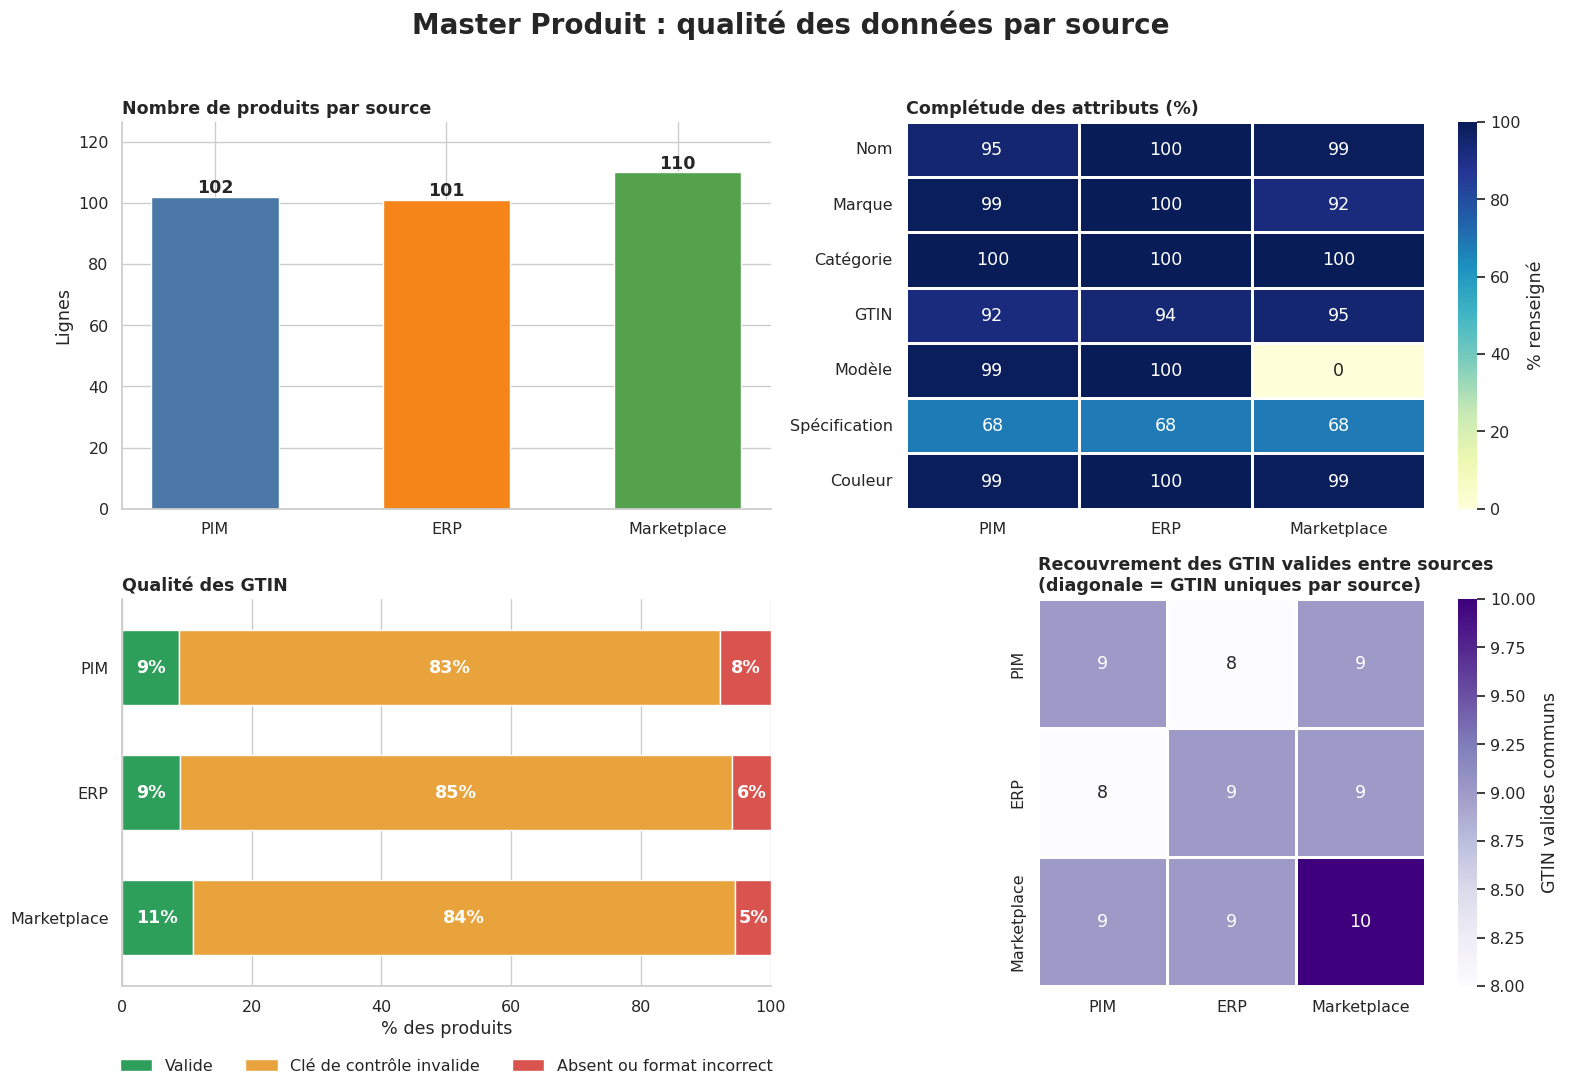

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------------
# Style
# ------------------------------------------------------------------
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

COULEURS = {"PIM": "#4C78A8", "ERP": "#F58518", "Marketplace": "#54A24B"}
sources = list(sources_h.keys())

# ------------------------------------------------------------------
# Données pour les graphiques
# ------------------------------------------------------------------
# 1) Volumes
volumes = pd.Series({n: len(df) for n, df in sources_h.items()})

# 2) Complétude par attribut (% de valeurs renseignées après normalisation)
attrs = {
    "product_name_norm": "Nom", "brand_norm": "Marque", "category_norm": "Catégorie",
    "gtin_norm": "GTIN", "model_norm": "Modèle",
    "specification_norm": "Spécification", "color_norm": "Couleur",
}
completude = pd.DataFrame({
    n: df[list(attrs)].notna().mean() * 100 for n, df in sources_h.items()
})
completude.index = list(attrs.values())

# 3) Qualité des GTIN
gtin_qualite = pd.DataFrame({
    n: {
        "Valide": df["gtin_valide"].mean() * 100,
        "Clé de contrôle invalide": (df["gtin_norm"].notna() & ~df["gtin_valide"]).mean() * 100,
        "Absent ou format incorrect": df["gtin_norm"].isna().mean() * 100,
    }
    for n, df in sources_h.items()
}).T

# 4) Recouvrement des GTIN valides entre sources
gtin_sets = {
    n: set(df.loc[df["gtin_valide"], "gtin_norm"].dropna()) for n, df in sources_h.items()
}
recouvrement = pd.DataFrame(
    [[len(gtin_sets[a] & gtin_sets[b]) for b in sources] for a in sources],
    index=sources, columns=sources,
)

# ------------------------------------------------------------------
# Tableau de bord
# ------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Master Produit : qualité des données par source",
             fontsize=20, fontweight="bold", y=0.99)

# --- 1. Volumes ---
ax = axes[0, 0]
bars = ax.bar(volumes.index, volumes.values,
              color=[COULEURS[s] for s in volumes.index], width=0.55)
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(),
            f"{int(b.get_height()):,}".replace(",", " "),
            ha="center", va="bottom", fontweight="bold")
ax.set_title("Nombre de produits par source", fontweight="bold", loc="left")
ax.set_ylabel("Lignes")
ax.set_ylim(0, volumes.max() * 1.15)

# --- 2. Complétude ---
ax = axes[0, 1]
sns.heatmap(completude, annot=True, fmt=".0f", cmap="YlGnBu", vmin=0, vmax=100,
            linewidths=2, linecolor="white", cbar_kws={"label": "% renseigné"}, ax=ax)
ax.set_title("Complétude des attributs (%)", fontweight="bold", loc="left")
ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)

# --- 3. Qualité des GTIN ---
ax = axes[1, 0]
palette = ["#2E9E5B", "#E8A33D", "#D9534F"]
gtin_qualite.plot(kind="barh", stacked=True, color=palette, width=0.6, ax=ax)
for container in ax.containers:
    labels = [f"{v:.0f}%" if v >= 4 else "" for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type="center",
                 color="white", fontweight="bold")
ax.set_title("Qualité des GTIN", fontweight="bold", loc="left")
ax.set_xlabel("% des produits"); ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
ax.invert_yaxis()

# --- 4. Recouvrement GTIN ---
ax = axes[1, 1]
sns.heatmap(recouvrement, annot=True, fmt="d", cmap="Purples",
            linewidths=2, linecolor="white", square=True,
            cbar_kws={"label": "GTIN valides communs"}, ax=ax)
ax.set_title("Recouvrement des GTIN valides entre sources\n(diagonale = GTIN uniques par source)",
             fontweight="bold", loc="left")
ax.set_xlabel(""); ax.set_ylabel("")

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig("dashboard_master_produit.png", dpi=150, bbox_inches="tight")
plt.show()

### 5. Fusionner les trois sources

In [69]:
donnees_harmonisees = pd.concat(
    [
        pim_h,
        erp_h,
        marketplace_h
    ],
    ignore_index=True,
    sort=False
)

print("Nombre total de lignes :", len(donnees_harmonisees))

display(donnees_harmonisees.head(10))

Nombre total de lignes : 313


,master_key,source_id,source_system,product_name,brand,category,gtin,model,specification,color,...,category_norm,model_norm,specification_norm,color_norm,gtin_norm,gtin_valide,seller_sku,seller_id,price_mad,stock_quantity
0,PIM_P0001,P0001,PIM,Samsung Galaxy S24 128 Go,Samsung,Smartphone,3700000000001,Galaxy S24,128 Go,Noir,...,smartphone,galaxy s24,128 go,noir,03700000000001,False,NaN,NaN,NaN,NaN
1,PIM_P0002,P0002,PIM,Apple iPhone 15 128 Go,Apple,Smartphone,3700000000002,iPhone 15,128 Go,Noir,...,smartphone,iphone 15,128 go,noir,03700000000002,False,NaN,NaN,NaN,NaN
2,PIM_P0003,P0003,PIM,Apple iPhone 15 Pro 256 Go,Apple,Smartphone,3700000000003,iPhone 15 Pro,256 Go,Titane,...,smartphone,iphone 15 pro,256 go,titane,03700000000003,False,NaN,NaN,NaN,NaN
3,PIM_P0004,P0004,PIM,Xiaomi Redmi Note 13 256 Go,Xiaomi,Smartphone,3700000000004,Redmi Note 13,256 Go,Noir,...,smartphone,redmi note 13,256 go,noir,03700000000004,False,NaN,NaN,NaN,NaN
4,PIM_P0005,P0005,PIM,Google Pixel 8 128 Go,Google,Smartphone,3700000000005,Pixel 8,128 Go,Noir,...,smartphone,pixel 8,128 go,noir,03700000000005,False,NaN,NaN,NaN,NaN
5,PIM_P0006,P0006,PIM,Sony WH-1000XM5,Sony,Casque audio,3700000000006,WH-1000XM5,NaN,Noir,...,casque audio,wh 1000xm5,<NA>,noir,03700000000006,True,NaN,NaN,NaN,NaN
6,PIM_P0007,P0007,PIM,JBL Tune 760NC,JBL,Casque audio,3700000000007,Tune 760NC,NaN,Noir,...,casque audio,tune 760nc,<NA>,noir,03700000000007,False,NaN,NaN,NaN,NaN
7,PIM_P0008,P0008,PIM,Apple AirPods Pro 2,Apple,Écouteurs,3700000000008,AirPods Pro 2,NaN,Blanc,...,ecouteurs,airpods pro 2,<NA>,blanc,03700000000008,False,NaN,NaN,NaN,NaN
8,PIM_P0009,P0009,PIM,Dell XPS 13 16 Go RAM / 512 Go SSD,Dell,Ordinateur portable,3700000000009,XPS 13,16 Go RAM / 512 Go SSD,Argent,...,ordinateur portable,xps 13,16 go ram 512 go ssd,argent,03700000000009,False,NaN,NaN,NaN,NaN
9,PIM_P0010,P0010,PIM,HP Pavilion 15 8 Go RAM / 512 Go SSD,HP,Ordinateur portable,3700000000010,Pavilion 15,8 Go RAM / 512 Go SSD,Argent,...,ordinateur portable,pavilion 15,8 go ram 512 go ssd,argent,03700000000010,False,NaN,NaN,NaN,NaN


In [70]:
print("Nombre de lignes :", len(donnees_harmonisees))

print("\nRépartition par source :")

display(
    donnees_harmonisees["source_system"].value_counts()
)

print("\nAperçu de la table fusionnée :")



Nombre de lignes : 313

Répartition par source :


source_system
Marketplace    110
PIM            102
ERP            101
Name: count, dtype: int64


Aperçu de la table fusionnée :


Nombre total de lignes : 313


source_system,source_id,product_name,brand,category,gtin,valide,model,specification,color
PIM,P0001,Samsung Galaxy S24 128 Go,Samsung,Smartphone,03700000000001,✘,Galaxy S24,128 Go,Noir
PIM,P0002,Apple iPhone 15 128 Go,Apple,Smartphone,03700000000002,✘,iPhone 15,128 Go,Noir
PIM,P0003,Apple iPhone 15 Pro 256 Go,Apple,Smartphone,03700000000003,✘,iPhone 15 Pro,256 Go,Titane
PIM,P0004,Xiaomi Redmi Note 13 256 Go,Xiaomi,Smartphone,03700000000004,✘,Redmi Note 13,256 Go,Noir
ERP,ART-1001,SAMSUNG - Galaxy S24 128 Go,SAMSUNG,Smartphone,03700000000001,✘,Galaxy S24,128 Go,Noir
ERP,ART-1002,APPLE - iPhone 15 128 Go,APPLE,Smartphone,03700000000002,✘,iPhone 15,128 Go,Noir
ERP,ART-1003,APPLE - iPhone 15 Pro 256 Go,APPLE,Smartphone,03700000000003,✘,iPhone 15 Pro,256 Go,Titane
ERP,ART-1004,XIAOMI - Redmi Note 13 256 Go,XIAOMI,Smartphone,03700000000004,✘,Redmi Note 13,256 Go,Noir
Marketplace,OFF-5001,Samsung Galaxy S24 128 Go,Samsung,Smartphone,03700000000001,✘,∅,128 Go,Noir
Marketplace,OFF-5002,Apple iPhone 15 128 Go,Apple,Smartphone,03700000000002,✘,∅,128 Go,Noir


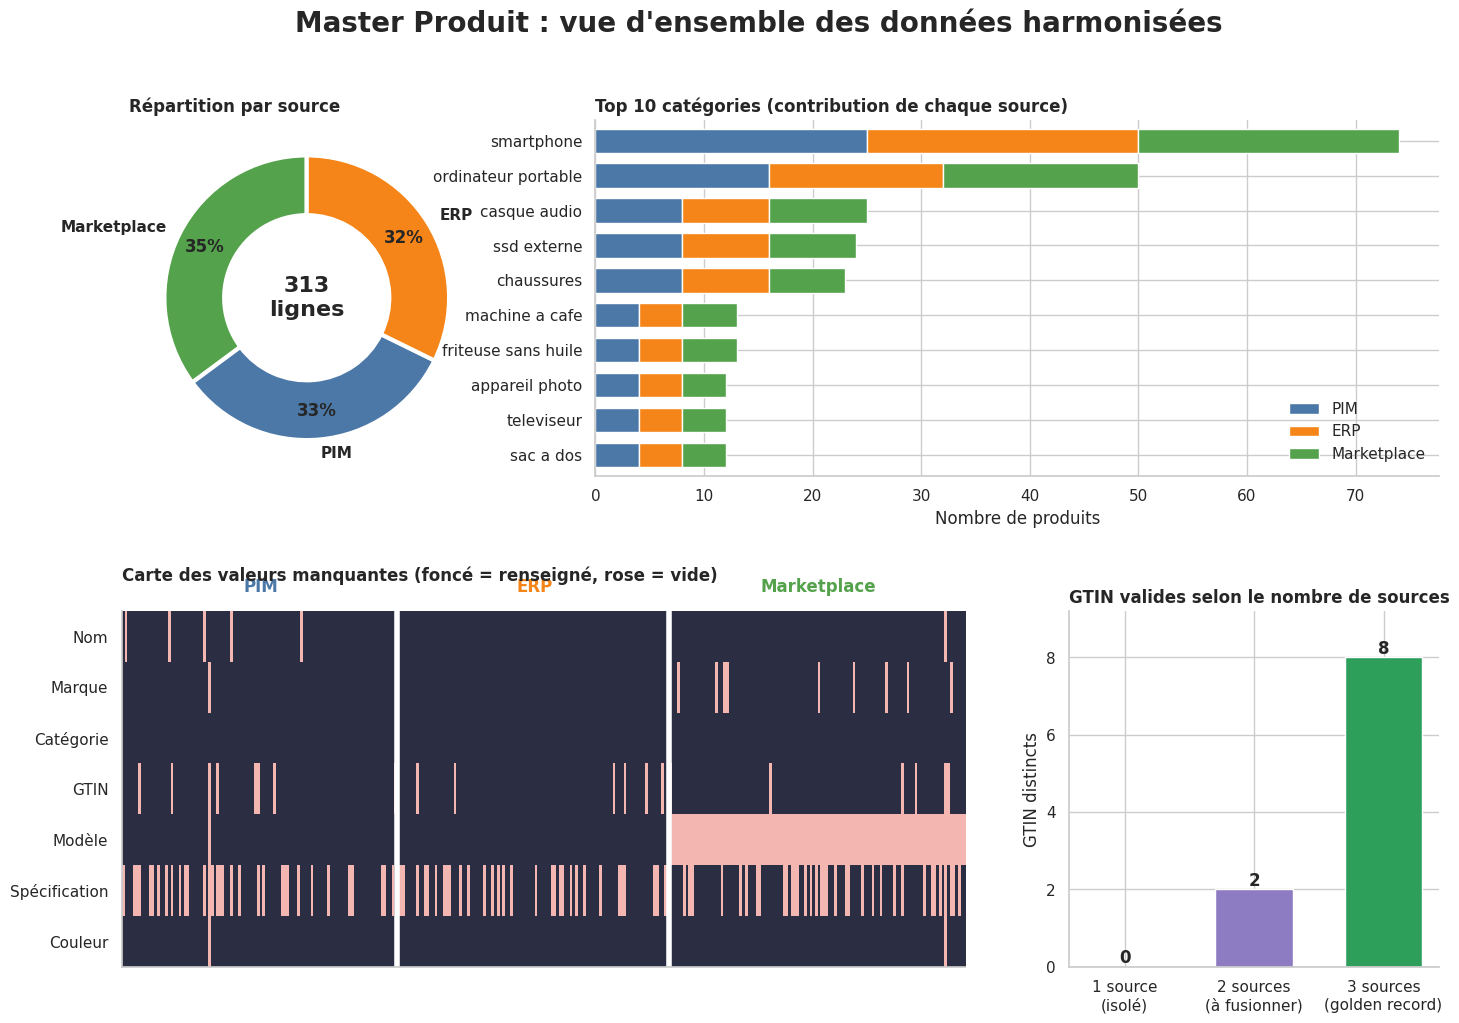

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.gridspec import GridSpec

donnees_harmonisees = pd.concat([pim_h, erp_h, marketplace_h], ignore_index=True, sort=False)
df = donnees_harmonisees
df["gtin_valide"] = df["gtin_valide"].fillna(False).astype(bool)

COULEURS = {"PIM": "#4C78A8", "ERP": "#F58518", "Marketplace": "#54A24B"}
print(f"Nombre total de lignes : {len(df):,}".replace(",", " "))

# ==================================================================
# PARTIE 1 : aperçu stylisé (4 lignes par source, pas 10 lignes du PIM)
# ==================================================================
cols = ["source_system", "source_id", "product_name", "brand", "category",
        "gtin_norm", "gtin_valide", "model", "specification", "color"]
apercu = df.groupby("source_system", sort=False).head(4)[cols].copy()
apercu["gtin_valide"] = apercu["gtin_valide"].map({True: "✔", False: "✘"})
apercu = apercu.rename(columns={"gtin_norm": "gtin", "gtin_valide": "valide"})

def badge_source(v):
    return f"background-color:{COULEURS.get(v, '#999')};color:white;font-weight:bold;text-align:center"

def badge_gtin(v):
    return ("color:#2E9E5B;font-weight:bold;text-align:center" if v == "✔"
            else "color:#D9534F;font-weight:bold;text-align:center")

def surligne_vide(col):
    return ["background-color:#FDE2E1;color:#B03A2E" if pd.isna(v) else "" for v in col]

styler = apercu.style
appliquer = getattr(styler, "map", None) or styler.applymap   # compatible pandas ancien/récent
styler = (
    appliquer(badge_source, subset=["source_system"])
    .map(badge_gtin, subset=["valide"]) if hasattr(styler, "map")
    else styler.applymap(badge_source, subset=["source_system"]).applymap(badge_gtin, subset=["valide"])
)
styler = (
    styler.apply(surligne_vide, axis=0)
    .format(na_rep="∅")
    .hide(axis="index")
    .set_caption("Aperçu du Master Produit (rouge = valeur manquante)")
    .set_table_styles([
        {"selector": "caption", "props": "font-size:16px;font-weight:bold;text-align:left;padding-bottom:8px"},
        {"selector": "th", "props": "background-color:#2B2D42;color:white;text-align:left;padding:6px 10px"},
        {"selector": "td", "props": "padding:5px 10px;border-bottom:1px solid #eee"},
    ])
)
display(styler)

# ==================================================================
# PARTIE 2 : tableau de bord
# ==================================================================
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

fig = plt.figure(figsize=(17, 11))
gs = GridSpec(2, 3, figure=fig, hspace=0.38, wspace=0.28)
fig.suptitle("Master Produit : vue d'ensemble des données harmonisées",
             fontsize=20, fontweight="bold", y=0.98)

# --- 1. Donut : répartition par source ---
ax = fig.add_subplot(gs[0, 0])
vol = df["source_system"].value_counts()
ax.pie(vol.values, labels=vol.index, colors=[COULEURS[s] for s in vol.index],
       autopct=lambda p: f"{p:.0f}%", startangle=90, pctdistance=0.8,
       wedgeprops=dict(width=0.42, edgecolor="white", linewidth=3),
       textprops=dict(fontweight="bold"))
ax.text(0, 0, f"{len(df):,}".replace(",", " ") + "\nlignes", ha="center", va="center",
        fontsize=16, fontweight="bold")
ax.set_title("Répartition par source", fontweight="bold", loc="left")

# --- 2. Top catégories, empilées par source ---
ax = fig.add_subplot(gs[0, 1:])
top_cat = df["category_norm"].value_counts().head(10).index
cat = (df[df["category_norm"].isin(top_cat)]
       .groupby(["category_norm", "source_system"]).size().unstack(fill_value=0)
       .reindex(top_cat)[[s for s in COULEURS if s in df["source_system"].unique()]])
cat.plot(kind="barh", stacked=True, ax=ax, width=0.7, color=[COULEURS[s] for s in cat.columns])
ax.invert_yaxis()
ax.set_title("Top 10 catégories (contribution de chaque source)", fontweight="bold", loc="left")
ax.set_xlabel("Nombre de produits"); ax.set_ylabel("")
ax.legend(title="", frameon=False, loc="lower right")

# --- 3. Matrice des valeurs manquantes (échantillon stratifié) ---
ax = fig.add_subplot(gs[1, :2])
attrs = {"product_name_norm": "Nom", "brand_norm": "Marque", "category_norm": "Catégorie",
         "gtin_norm": "GTIN", "model_norm": "Modèle", "specification_norm": "Spécification",
         "color_norm": "Couleur"}
ech = pd.concat([g.sample(min(len(g), 120), random_state=42)
                 for _, g in df.groupby("source_system", sort=False)])
matrice = ech[list(attrs)].notna().to_numpy().T.astype(int)
ax.imshow(matrice, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(["#F4B6B0", "#2B2D42"]))
ax.set_yticks(range(len(attrs))); ax.set_yticklabels(attrs.values())
ax.set_xticks([]); ax.grid(False)

debut = 0
for nom, g in ech.groupby("source_system", sort=False):
    n = len(g)
    if debut > 0:
        ax.axvline(debut - 0.5, color="white", lw=4)
    ax.text(debut + n / 2, -0.8, nom, ha="center", va="bottom",
            color=COULEURS[nom], fontweight="bold", fontsize=12)
    debut += n
ax.set_title("\nCarte des valeurs manquantes (foncé = renseigné, rose = vide)",
             fontweight="bold", loc="left", pad=22)

# --- 4. Potentiel de rapprochement par GTIN ---
ax = fig.add_subplot(gs[1, 2])
valides = df[df["gtin_valide"]]
nb_sources = valides.groupby("gtin_norm")["source_system"].nunique()
compte = nb_sources.value_counts().reindex([1, 2, 3], fill_value=0)
etiquettes = ["1 source\n(isolé)", "2 sources\n(à fusionner)", "3 sources\n(golden record)"]
barres = ax.bar(etiquettes, compte.values, color=["#BDBDBD", "#8E7CC3", "#2E9E5B"], width=0.6)
for b in barres:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{int(b.get_height()):,}".replace(",", " "),
            ha="center", va="bottom", fontweight="bold")
ax.set_ylim(0, max(compte.max() * 1.15, 1))
ax.set_title("GTIN valides selon le nombre de sources", fontweight="bold", loc="left")
ax.set_ylabel("GTIN distincts")

plt.savefig("apercu_master_produit.png", dpi=150, bbox_inches="tight")
plt.show()